In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 10장 케라스를 사용한 인공 신경망 소개

## 10.1 생물학적 뉴런에서 인공 뉴런까지

### 10.1.3 퍼셉트론

In [2]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X = iris.data[['petal length (cm)', 'petal width (cm)']].values
y = (iris.target == 0)

In [3]:
from sklearn.linear_model import Perceptron

per_clf = Perceptron(random_state=42)
per_clf.fit(X, y)

,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [4]:
X_new = [[2, 0.5], [3, 1]]
y_pred = per_clf.predict(X_new)

y_pred

array([ True, False])

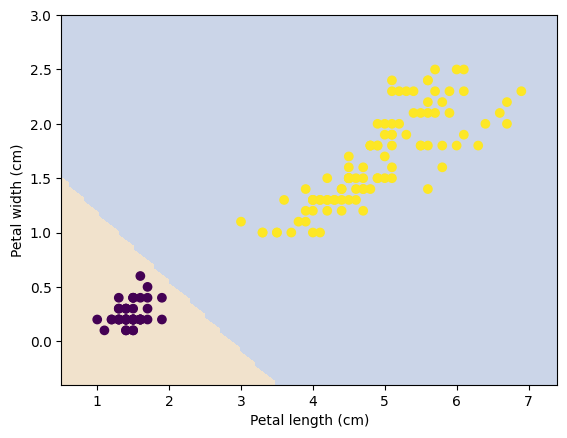

In [5]:
mins = X.min(axis=0) - 0.5
maxs = X.max(axis=0) + 0.5

xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], 100),
                     np.linspace(mins[1], maxs[1], 100))
Z = per_clf.predict(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]), cmap='Pastel2')
plt.scatter(X[:,0], X[:,1], c=-y)
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.show()

### 10.1.5 회귀를 위한 다층 퍼셉트론

In [6]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

housing = fetch_california_housing()
X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42)

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_valid)
rmse = root_mean_squared_error(y_valid, y_pred)

rmse

0.505332665796875

### 10.1.6 분류를 위한 다층 퍼셉트론

In [8]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    iris.data, iris.target, test_size=0.1, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.1, random_state=42)

In [9]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

mlp_clf = MLPClassifier(hidden_layer_sizes=[5], max_iter=5000, random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_clf)
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_valid)
accuracy = accuracy_score(y_pred, y_valid)

accuracy

1.0

## 10.2 케라스로 다층 퍼셉트론 구현하기

### 10.2.1 시퀀셜 API로 이미지 분류기 만들기

#### 케라스로 데이터셋 적재하기

In [10]:
import tensorflow as tf

fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()

(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]

In [11]:
X_train.shape

(55000, 28, 28)

In [12]:
X_train.dtype

dtype('uint8')

In [13]:
X_train, X_valid, X_test = X_train / 255, X_valid / 255, X_test / 255

In [14]:
X_train.dtype

dtype('float64')

In [15]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

class_names[y_train[0]]

'Ankle boot'

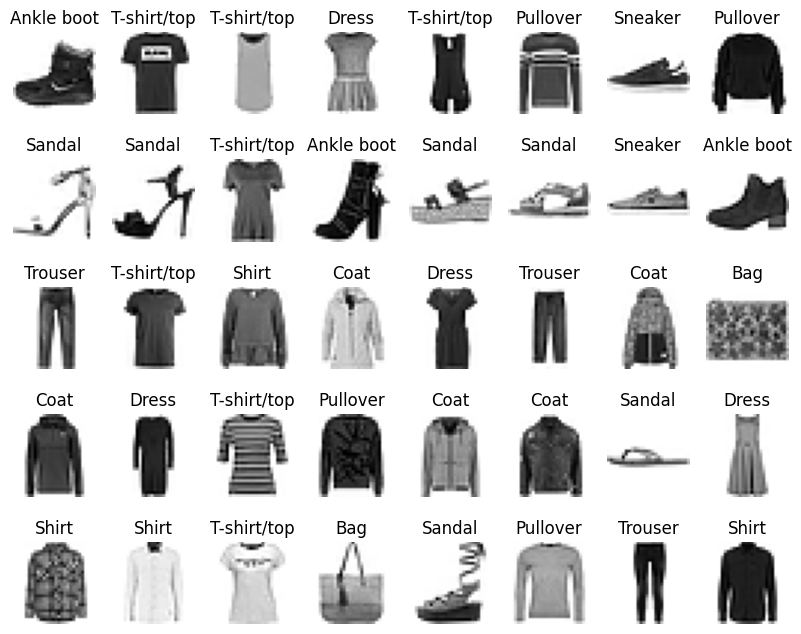

In [16]:
plt.figure(figsize=(10, 8))
for i in range(40):
    plt.subplot(5, 8, i+1)
    plt.imshow(X_train[i], cmap='binary')
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.show()

#### 시퀀셜 API로 모델 만들기

In [17]:
tf.random.set_seed(42)

In [18]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=[28, 28]))
model.add(tf.keras.layers.Flatten())
model.add(tf.keras.layers.Dense(300, activation='relu'))
model.add(tf.keras.layers.Dense(100, activation='relu'))
model.add(tf.keras.layers.Dense(10, activation='softmax'))

In [19]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=[28, 28]),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(300, activation='relu'),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [20]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.layers

[<Flatten name=flatten_1, built=True>,
 <Dense name=dense_3, built=True>,
 <Dense name=dense_4, built=True>,
 <Dense name=dense_5, built=True>]

In [22]:
hidden1 = model.layers[1]
hidden1.name

'dense_3'

In [23]:
model.get_layer('dense_3') is hidden1

True

In [24]:
weights, biases = hidden1.get_weights()

In [25]:
weights

array([[ 0.04020808, -0.03862721, -0.03351862, ..., -0.05467277,
        -0.0263654 ,  0.03170244],
       [ 0.01880145,  0.00688743, -0.06198968, ..., -0.0575159 ,
         0.00090334, -0.04271808],
       [ 0.02542718,  0.02427239, -0.05845928, ...,  0.0188986 ,
        -0.03348011,  0.0407301 ],
       ...,
       [-0.05577216,  0.01413466,  0.07006751, ..., -0.06848681,
        -0.03599161, -0.01795631],
       [-0.03684434, -0.03013326, -0.04377969, ...,  0.06135288,
         0.03970477,  0.06077422],
       [-0.05164926, -0.03074573, -0.04151018, ..., -0.03247294,
         0.01874792,  0.06994797]], shape=(784, 300), dtype=float32)

In [26]:
weights.shape

(784, 300)

In [27]:
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [28]:
biases.shape

(300,)

In [29]:
hidden1.set_weights([weights, biases])

In [30]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(300, activation='relu'),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [31]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=[28, 28]),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(300, activation='relu'),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

#### 모델 컴파일

In [32]:
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='sgd',
              metrics=['accuracy'])

In [33]:
model.compile(loss=tf.keras.losses.sparse_categorical_crossentropy,
              optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
              metrics=[tf.keras.metrics.sparse_categorical_accuracy])

#### 모델 훈련과 평가

In [34]:
history = model.fit(X_train, y_train, epochs=30, validation_data=(X_valid, y_valid))

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 841us/step - loss: 0.6999 - sparse_categorical_accuracy: 0.7646 - val_loss: 0.5054 - val_sparse_categorical_accuracy: 0.8310
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 785us/step - loss: 0.4862 - sparse_categorical_accuracy: 0.8311 - val_loss: 0.4562 - val_sparse_categorical_accuracy: 0.8404
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 780us/step - loss: 0.4404 - sparse_categorical_accuracy: 0.8478 - val_loss: 0.4302 - val_sparse_categorical_accuracy: 0.8494
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 783us/step - loss: 0.4126 - sparse_categorical_accuracy: 0.8566 - val_loss: 0.4133 - val_sparse_categorical_accuracy: 0.8518
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 782us/step - loss: 0.3923 - sparse_categorical_accuracy: 0.8628 - val_loss: 0.4019 - val_sparse_categorical_accuracy: 0.8558
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 790us/step - loss: 0.3761 - sparse_categorical_accuracy: 0.8686 - val_loss: 0.3918 - val_sparse_categoric

In [35]:
history.params

{'verbose': 'auto', 'epochs': 30, 'steps': 1719}

In [36]:
print(history.epoch)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


In [37]:
history.history.keys()

dict_keys(['loss', 'sparse_categorical_accuracy', 'val_loss', 'val_sparse_categorical_accuracy'])

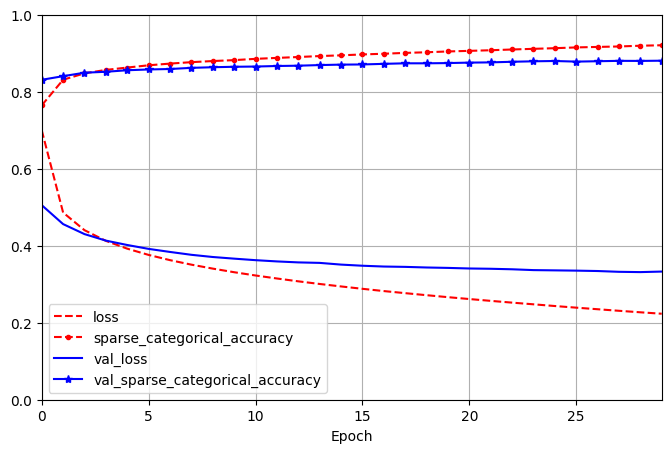

In [38]:
pd.DataFrame(history.history).plot(
    figsize=(8, 5), xlim=[0, 29], ylim=[0, 1], grid=True, xlabel='Epoch',
    style=['r--', 'r--.', 'b-', 'b-*'])
plt.show()

In [39]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 477us/step - loss: 0.3601 - sparse_categorical_accuracy: 0.8748


[0.3601281940937042, 0.8748000264167786]

#### 모델로 예측 만들기

In [40]:
X_new = X_test[:3]
y_proba = model.predict(X_new)

y_proba.round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.24, 0.  , 0.01, 0.  , 0.75],
       [0.  , 0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ]],
      dtype=float32)

In [41]:
y_pred = y_proba.argmax(axis=1)
y_pred

array([9, 2, 1])

In [42]:
np.array(class_names)[y_pred]

array(['Ankle boot', 'Pullover', 'Trouser'], dtype='<U11')

In [43]:
y_new = y_test[:3]
y_new

array([9, 2, 1], dtype=uint8)

### 10.2.2 시퀀셜 API로 회귀용 다층 퍼셉트론 만들기

In [44]:
housing = fetch_california_housing()
X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42)

In [45]:
tf.random.set_seed(42)

In [46]:
norm_layer = tf.keras.layers.Normalization()
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=X_train.shape[1:]),
    norm_layer,
    tf.keras.layers.Dense(50, activation='relu'),
    tf.keras.layers.Dense(50, activation='relu'),
    tf.keras.layers.Dense(50, activation='relu'),
    tf.keras.layers.Dense(1)
])

norm_layer.adapt(X_train)

In [47]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss='mse', optimizer=optimizer, metrics=['RootMeanSquaredError'])

history = model.fit(X_train, y_train, epochs=20, validation_data=(X_test, y_test))

Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - RootMeanSquaredError: 0.9598 - loss: 0.9213 - val_RootMeanSquaredError: 0.6390 - val_loss: 0.4084
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 570us/step - RootMeanSquaredError: 0.6265 - loss: 0.3926 - val_RootMeanSquaredError: 0.6035 - val_loss: 0.3642
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 571us/step - RootMeanSquaredError: 0.6008 - loss: 0.3610 - val_RootMeanSquaredError: 0.5944 - val_loss: 0.3533
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 568us/step - RootMeanSquaredError: 0.5873 - loss: 0.3450 - val_RootMeanSquaredError: 0.5853 - val_loss: 0.3426
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 566us/step - RootMeanSquaredError: 0.5806 - loss: 0.3371 - val_RootMeanSquaredError: 0.5813 - val_loss: 0.3379
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 575us/step - RootMeanSquaredError: 0.5698 - loss: 0.3247 - val_RootMeanSquaredError: 0.5713 - val_loss: 0.3264
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 567us/step - RootMeanSquaredError: 

In [48]:
X_new = X_test[:3]
y_pred = model.predict(X_new)

y_pred.round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


array([[0.58],
       [1.08],
       [4.74]], dtype=float32)

### 10.2.3 함수형 API로 복잡한 모뎁 만들기

In [49]:
normalization_layer = tf.keras.layers.Normalization()
hidden_layer1 = tf.keras.layers.Dense(30, activation='relu')
hidden_layer2 = tf.keras.layers.Dense(30, activation='relu')
concat_layer = tf.keras.layers.Concatenate()
output_layer = tf.keras.layers.Dense(1)

input_ = tf.keras.layers.Input(shape=X_train.shape[1:])
normalized = normalization_layer(input_)
hidden1 = hidden_layer1(normalized)
hidden2 = hidden_layer2(hidden1)
concat = concat_layer([normalized, hidden2])
output = output_layer(concat)

model = tf.keras.Model(inputs=[input_], outputs=[output])

In [50]:
model.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_1     │ (None, 8)         │         17 │ input_layer_4[0]… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 30)        │        270 │ normalization_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 30)        │        930 │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 38)        │          0 │ normalization_1[… │
│ (Concatenate)       │                   │            │ dense_17[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_18 (Dense)    │ (None, 1)         │         39 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,256 (4.91 KB)

 Trainable params: 1,239 (4.84 KB)

 Non-trainable params: 17 (72.00 B)

In [51]:
input_wide = tf.keras.layers.Input(shape=[5])
input_deep = tf.keras.layers.Input(shape=[6])

norm_layer_wide = tf.keras.layers.Normalization()
norm_layer_deep = tf.keras.layers.Normalization()
norm_wide = norm_layer_wide(input_wide)
norm_deep = norm_layer_deep(input_deep)

hidden1 = tf.keras.layers.Dense(30, activation='relu')(norm_deep)
hidden2 = tf.keras.layers.Dense(30, activation='relu')(hidden1)

concat = tf.keras.layers.Concatenate()([norm_wide, hidden2])
output = tf.keras.layers.Dense(1)(concat)

model = tf.keras.Model(inputs=[input_wide, input_deep], outputs=[output])

In [52]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss='mse', optimizer=optimizer, metrics=['RootMeanSquaredError'])

X_train_wide, X_train_deep = X_train[:, :5], X_train[:, 2:]
X_valid_wide, X_valid_deep = X_valid[:, :5], X_valid[:, 2:]
X_test_wide, X_test_deep = X_test[:, :5], X_test[:, 2:]
X_new_wide, X_new_deep = X_new[:, :5], X_new[:, 2:]

norm_layer_wide.adapt(X_train_wide)
norm_layer_deep.adapt(X_train_deep)

history = model.fit((X_train_wide, X_train_deep), y_train, epochs=20,
                    validation_data=((X_valid_wide, X_valid_deep), y_valid))

Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 763us/step - RootMeanSquaredError: 1.2225 - loss: 1.4945 - val_RootMeanSquaredError: 1.7840 - val_loss: 3.1826
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 518us/step - RootMeanSquaredError: 0.7115 - loss: 0.5063 - val_RootMeanSquaredError: 0.8268 - val_loss: 0.6835
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 518us/step - RootMeanSquaredError: 0.6505 - loss: 0.4232 - val_RootMeanSquaredError: 0.6524 - val_loss: 0.4256
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 516us/step - RootMeanSquaredError: 0.6291 - loss: 0.3957 - val_RootMeanSquaredError: 0.6014 - val_loss: 0.3617
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 516us/step - RootMeanSquaredError: 0.6172 - loss: 0.3810 - val_RootMeanSquaredError: 0.6470 - val_loss: 0.4186
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 516us/step - RootMeanSquaredError: 0.6107 - loss: 0.3729 - val_RootMeanSquaredError: 0.6050 - val_loss: 0.3660
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 514us/step - RootMeanSquaredError

In [53]:
mse_test = model.evaluate((X_test_wide, X_test_deep), y_test)

mse_test

162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 336us/step - RootMeanSquaredError: 0.5747 - loss: 0.3303


[0.33025750517845154, 0.5746803283691406]

In [54]:
y_pred = model.predict((X_new_wide, X_new_deep))

y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


array([[0.3460555],
       [1.2479724],
       [3.5529492]], dtype=float32)

In [55]:
input_wide = tf.keras.layers.Input(shape=[5])
input_deep = tf.keras.layers.Input(shape=[6])

norm_layer_wide = tf.keras.layers.Normalization()
norm_layer_deep = tf.keras.layers.Normalization()
norm_wide = norm_layer_wide(input_wide)
norm_deep = norm_layer_deep(input_deep)

hidden1 = tf.keras.layers.Dense(30, activation='relu')(norm_deep)
hidden2 = tf.keras.layers.Dense(30, activation='relu')(hidden1)

concat = tf.keras.layers.Concatenate()([norm_wide, hidden2])
output = tf.keras.layers.Dense(1)(concat)
aux_output = tf.keras.layers.Dense(1)(hidden2)

model = tf.keras.Model(inputs=[input_wide, input_deep], outputs=[output, aux_output])

In [56]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss=('mse', 'mse'), loss_weights=(0.9, 0.1), optimizer=optimizer,
              metrics=['RootMeanSquaredError', 'RootMeanSquaredError'])

norm_layer_wide.adapt(X_train_wide)
norm_layer_deep.adapt(X_train_deep)

history = model.fit((X_train_wide, X_train_deep), (y_train, y_train), epochs=20,
                    validation_data=((X_valid_wide, X_valid_deep), (y_valid, y_valid)))

Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 998us/step - dense_24_RootMeanSquaredError: 1.1861 - dense_24_loss: 1.4064 - dense_25_RootMeanSquaredError: 1.6053 - dense_25_loss: 2.5762 - loss: 1.5239 - val_dense_24_RootMeanSquaredError: 0.8120 - val_dense_24_loss: 0.6592 - val_dense_25_RootMeanSquaredError: 2.0005 - val_dense_25_loss: 4.0003 - val_loss: 0.9937
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 616us/step - dense_24_RootMeanSquaredError: 0.7251 - dense_24_loss: 0.5258 - dense_25_RootMeanSquaredError: 0.9150 - dense_25_loss: 0.8371 - loss: 0.5569 - val_dense_24_RootMeanSquaredError: 0.7252 - val_dense_24_loss: 0.5258 - val_dense_25_RootMeanSquaredError: 1.0208 - val_dense_25_loss: 1.0417 - val_loss: 0.5776
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 617us/step - dense_24_RootMeanSquaredError: 0.6674 - dense_24_loss: 0.4455 - dense_25_RootMeanSquaredError: 0.7811 - dense_25_loss: 0.6101 - loss: 0.4619 - val_dense_24_RootMeanSquaredError: 0.6822 - val_dense_24_loss: 0.4652 - val_dense

In [57]:
eval_results = model.evaluate((X_test_wide, X_test_deep), (y_test, y_test))
weighted_sum_of_losses, main_loss, aux_loss, main_rmse, aux_rmse = eval_results

162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 415us/step - dense_24_RootMeanSquaredError: 0.5915 - dense_24_loss: 0.3497 - dense_25_RootMeanSquaredError: 0.6523 - dense_25_loss: 0.4260 - loss: 0.3575


In [58]:
eval_results = model.evaluate((X_test_wide, X_test_deep), (y_test, y_test), return_dict=True)

eval_results

162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 419us/step - dense_24_RootMeanSquaredError: 0.5915 - dense_24_loss: 0.3497 - dense_25_RootMeanSquaredError: 0.6523 - dense_25_loss: 0.4260 - loss: 0.3575


{'dense_24_RootMeanSquaredError': 0.5915314555168152,
 'dense_24_loss': 0.34968650341033936,
 'dense_25_RootMeanSquaredError': 0.6523041129112244,
 'dense_25_loss': 0.42599576711654663,
 'loss': 0.35746851563453674}

In [59]:
y_pred_main, y_pred_aux = model.predict((X_new_wide, X_new_deep))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


In [60]:
model.output_names

ListWrapper(['dense_24', 'dense_25'])

In [61]:
y_pred_tuple = model.predict((X_new_wide, X_new_deep))
y_pred = dict(zip(model.output_names, y_pred_tuple))

y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


{'dense_24': array([[0.2520759],
        [1.1716222],
        [3.3988426]], dtype=float32),
 'dense_25': array([[0.39664292],
        [1.2285397 ],
        [3.157132  ]], dtype=float32)}

### 10.2.4 서브클래스 API로 동적 모델 만들기

In [62]:
import keras

@keras.saving.register_keras_serializable()
class WideAndDeepModel(tf.keras.Model):
    def __init__(self, units=30, activation='relu', **kwargs):
        super().__init__(**kwargs)
        self.norm_layer_wide = tf.keras.layers.Normalization()
        self.norm_layer_deep = tf.keras.layers.Normalization()
        self.hidden1 = tf.keras.layers.Dense(units, activation=activation)
        self.hidden2 = tf.keras.layers.Dense(units, activation=activation)
        self.main_output = tf.keras.layers.Dense(1)
        self.aux_output = tf.keras.layers.Dense(1)

    def call(self, inputs):
        input_wide, input_deep = inputs
        norm_wide = self.norm_layer_wide(input_wide)
        norm_deep = self.norm_layer_deep(input_deep)
        hidden1 = self.hidden1(norm_deep)
        hidden2 = self.hidden2(hidden1)
        concat = tf.keras.layers.concatenate([norm_wide, hidden2])
        output = self.main_output(concat)
        aux_output = self.aux_output(hidden2)
        return output, aux_output

model = WideAndDeepModel(30, activation='relu', name='my_cool_model')

In [63]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss=('mse', 'mse'), loss_weights=(0.9, 0.1), optimizer=optimizer,
              metrics=['RootMeanSquaredError', 'RootMeanSquaredError'])

model.norm_layer_wide.adapt(X_train_wide)
model.norm_layer_deep.adapt(X_train_deep)

history = model.fit((X_train_wide, X_train_deep), (y_train, y_train), epochs=20,
                    validation_data=((X_valid_wide, X_valid_deep), (y_valid, y_valid)))

Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 981us/step - RootMeanSquaredError: 1.3680 - RootMeanSquaredError_1: 1.5420 - loss: 1.9220 - mse_loss: 2.3771 - val_RootMeanSquaredError: 0.7916 - val_RootMeanSquaredError_1: 1.4055 - val_loss: 0.7615 - val_mse_loss: 1.9747
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 601us/step - RootMeanSquaredError: 0.7239 - RootMeanSquaredError_1: 0.9059 - loss: 0.5537 - mse_loss: 0.8205 - val_RootMeanSquaredError: 0.7078 - val_RootMeanSquaredError_1: 0.8366 - val_loss: 0.5209 - val_mse_loss: 0.6998
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 597us/step - RootMeanSquaredError: 0.6758 - RootMeanSquaredError_1: 0.7857 - loss: 0.4727 - mse_loss: 0.6174 - val_RootMeanSquaredError: 0.6512 - val_RootMeanSquaredError_1: 0.7597 - val_loss: 0.4394 - val_mse_loss: 0.5770
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 599us/step - RootMeanSquaredError: 0.6497 - RootMeanSquaredError_1: 0.7462 - loss: 0.4356 - mse_loss: 0.5567 - val_RootMeanSquaredError: 0.6279 - val_RootMeanS

### 10.2.5 모델 저장과 복원하기

In [64]:
model.save('my_keras_model.keras')

In [65]:
model = tf.keras.models.load_model('my_keras_model.keras')

model

<WideAndDeepModel name=my_cool_model, built=True>

In [66]:
y_pred_main, y_pred_aux = model.predict((X_new_wide, X_new_deep))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


### 10.2.6 콜백 사용하기

In [67]:
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint('my_checkpoints.weights.h5',
                                                   save_weights_only=True)
history = model.fit((X_train_wide, X_train_deep), (y_train, y_train), epochs=20,
                    validation_data=((X_valid_wide, X_valid_deep), (y_valid, y_valid)),
                    callbacks=[checkpoint_cb])

Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - RootMeanSquaredError: 0.5749 - RootMeanSquaredError_1: 0.6289 - loss: 0.3370 - mse_loss: 0.3955 - val_RootMeanSquaredError: 0.5958 - val_RootMeanSquaredError_1: 0.6407 - val_loss: 0.3605 - val_mse_loss: 0.4105
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 629us/step - RootMeanSquaredError: 0.5728 - RootMeanSquaredError_1: 0.6259 - loss: 0.3345 - mse_loss: 0.3918 - val_RootMeanSquaredError: 0.7258 - val_RootMeanSquaredError_1: 0.8159 - val_loss: 0.5406 - val_mse_loss: 0.6655
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 624us/step - RootMeanSquaredError: 0.5733 - RootMeanSquaredError_1: 0.6253 - loss: 0.3349 - mse_loss: 0.3910 - val_RootMeanSquaredError: 0.6917 - val_RootMeanSquaredError_1: 0.8425 - val_loss: 0.5016 - val_mse_loss: 0.7097
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 626us/step - RootMeanSquaredError: 0.5706 - RootMeanSquaredError_1: 0.6232 - loss: 0.3319 - mse_loss: 0.3884 - val_RootMeanSquaredError: 0.7933 - val_RootMeanSqu

In [68]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=10, verbose=1,
                                                     restore_best_weights=True)
history = model.fit((X_train_wide, X_train_deep), (y_train, y_train), epochs=100,
                    validation_data=((X_valid_wide, X_valid_deep), (y_valid, y_valid)),
                    callbacks=[checkpoint_cb, early_stopping_cb])

Epoch 1/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 683us/step - RootMeanSquaredError: 0.5565 - RootMeanSquaredError_1: 0.6023 - loss: 0.3150 - mse_loss: 0.3628 - val_RootMeanSquaredError: 0.6648 - val_RootMeanSquaredError_1: 0.6683 - val_loss: 0.4424 - val_mse_loss: 0.4465
Epoch 2/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 628us/step - RootMeanSquaredError: 0.5555 - RootMeanSquaredError_1: 0.5996 - loss: 0.3136 - mse_loss: 0.3596 - val_RootMeanSquaredError: 0.7156 - val_RootMeanSquaredError_1: 0.8265 - val_loss: 0.5292 - val_mse_loss: 0.6830
Epoch 3/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 626us/step - RootMeanSquaredError: 0.5537 - RootMeanSquaredError_1: 0.5987 - loss: 0.3118 - mse_loss: 0.3585 - val_RootMeanSquaredError: 0.5859 - val_RootMeanSquaredError_1: 0.6506 - val_loss: 0.3513 - val_mse_loss: 0.4233
Epoch 4/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 622us/step - RootMeanSquaredError: 0.5528 - RootMeanSquaredError_1: 0.5968 - loss: 0.3106 - mse_loss: 0.3563 - val_RootMeanSquaredError: 0.6221 - val_RootM

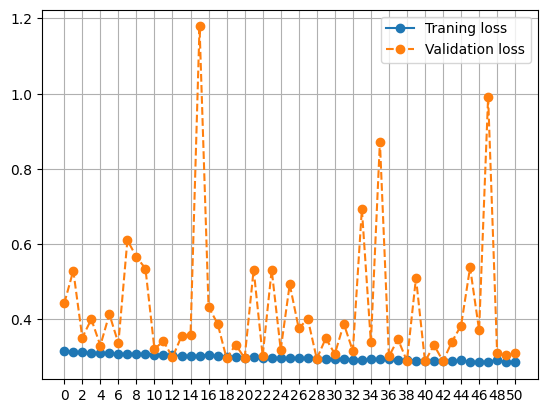

In [69]:
plt.plot(history.history['loss'], '-o', label='Traning loss')
plt.plot(history.history['val_loss'], '--o', label='Validation loss')
plt.xticks(range(0, history.epoch[-1] + 1, 2))
plt.grid()
plt.legend()
plt.show()

In [70]:
class PrintValTrainRatioCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs):
        ratio = logs['val_loss'] / logs['loss']
        print(f'Epoch={epoch}, val/train={ratio:.2f}')

In [71]:
history = model.fit((X_train_wide, X_train_deep), (y_train, y_train), epochs=20,
                    validation_data=((X_valid_wide, X_valid_deep), (y_valid, y_valid)),
                    callbacks=[PrintValTrainRatioCallback()],
                    verbose=0)

Epoch=0, val/train=1.24
Epoch=1, val/train=1.05
Epoch=2, val/train=1.03
Epoch=3, val/train=1.04
Epoch=4, val/train=1.38
Epoch=5, val/train=1.29
Epoch=6, val/train=3.35
Epoch=7, val/train=0.99
Epoch=8, val/train=2.16
Epoch=9, val/train=1.37
Epoch=10, val/train=1.16
Epoch=11, val/train=1.28
Epoch=12, val/train=1.64
Epoch=13, val/train=1.15
Epoch=14, val/train=1.48
Epoch=15, val/train=1.39
Epoch=16, val/train=1.41
Epoch=17, val/train=1.30
Epoch=18, val/train=2.00
Epoch=19, val/train=1.06


## 10.3 신경망 하이퍼파라미터 튜닝하기

In [72]:
import keras_tuner as kt

def build_model(hp):
    n_hidden = hp.Int('n_hidden', min_value=0, max_value=8, default=2)
    n_neurons = hp.Int('n_neurons', min_value=16, max_value=256)
    learning_rate = hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='log')
    optimizer = hp.Choice('optimizer', values=['sgd', 'adam'])
    if optimizer == 'sgd':
        optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate)
    else:
        optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Flatten())
    for _ in range(n_hidden):
        model.add(tf.keras.layers.Dense(n_neurons, activation='relu'))
    model.add(tf.keras.layers.Dense(10, activation='softmax'))
        
    model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])
    return model

In [73]:
random_search_tuner = kt.RandomSearch(
    build_model, objective='val_accuracy', max_trials=5, overwrite=True,
    directory='my_fashion_mnist', project_name='my_rnd_search', seed=42)
random_search_tuner.search(X_train, y_train, epochs=10, validation_data=(X_valid, y_valid))

Trial 5 Complete [00h 00m 03s]
val_accuracy: 0.004392764996737242

Best val_accuracy So Far: 0.004651162773370743
Total elapsed time: 00h 00m 15s


In [74]:
top3_models = random_search_tuner.get_best_models(num_models=3)
best_model = top3_models[0]

best_model

<Sequential name=sequential, built=True>

In [75]:
top3_params = random_search_tuner.get_best_hyperparameters(num_trials=3)

top3_params[0].values

{'n_hidden': 4,
 'n_neurons': 74,
 'learning_rate': 0.00905127409782462,
 'optimizer': 'adam'}

In [76]:
best_trial = random_search_tuner.oracle.get_best_trials(num_trials=1)[0]
best_trial.summary()

Trial 2 summary
Hyperparameters:
n_hidden: 4
n_neurons: 74
learning_rate: 0.00905127409782462
optimizer: adam
Score: 0.004651162773370743


In [77]:
best_trial.metrics.get_last_value('val_accuracy')

np.float64(0.004651162773370743)

In [78]:
best_model.fit(X_train_full, y_train_full, epochs=10)
test_loss, test_accuarcy = best_model.evaluate(X_test, y_test)

test_loss, test_accuarcy

Epoch 1/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 1s 482us/step - accuracy: 0.0033 - loss: 1.5273
Epoch 2/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 478us/step - accuracy: 0.0032 - loss: 1.5231
Epoch 3/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 478us/step - accuracy: 0.0033 - loss: 1.5161
Epoch 4/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 481us/step - accuracy: 0.0033 - loss: 1.5159
Epoch 5/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 480us/step - accuracy: 0.0033 - loss: 1.5157
Epoch 6/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 480us/step - accuracy: 0.0033 - loss: 1.5156
Epoch 7/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 488us/step - accuracy: 0.0033 - loss: 1.5155
Epoch 8/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 480us/step - accuracy: 0.0033 - loss: 1.5154
Epoch 9/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step - accuracy: 0.0033 - loss: 1.5154
Epoch 10/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 481us/step - accuracy: 0.0033 - loss: 1.5156
162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 380us/step - accuracy: 0.0021 - loss: 1.5136


(1.5136276483535767, 0.0021317829377949238)

In [79]:
class MyClassificationHyperModel(kt.HyperModel):
    def build(self, hp):
        # same as 'return build_model(hp)'
        n_hidden = hp.Int('n_hidden', min_value=0, max_value=8, default=2)
        n_neurons = hp.Int('n_neurons', min_value=16, max_value=256)
        learning_rate = hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='log')
        optimizer = hp.Choice('optimizer', values=['sgd', 'adam'])
        if optimizer == 'sgd':
            optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate)
        else:
            optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    
        model = tf.keras.Sequential()
        model.add(tf.keras.layers.Flatten())
        for _ in range(n_hidden):
            model.add(tf.keras.layers.Dense(n_neurons, activation='relu'))
        model.add(tf.keras.layers.Dense(10, activation='softmax'))
            
        model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])
        return model

    def fit(self, hp, model, X, y, **kwargs):
        if hp.Boolean('normalize'):
            norm_layer = tf.keras.layers.Normalization()
            X = norm_layer(X)
        return model.fit(X, y, **kwargs)

In [80]:
hyperband_tuner = kt.Hyperband(
    MyClassificationHyperModel(), objective='val_accuracy', seed=42,
    max_epochs=10, factor=3, hyperband_iterations=2,
    overwrite=True, directory='my_fashion_mnist', project_name='hyperband')

In [81]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=2)
hyperband_tuner.search(X_train, y_train, epochs=10,
                       validation_data=(X_valid, y_valid),
                       callbacks=[early_stopping_cb])

Trial 60 Complete [00h 00m 02s]
val_accuracy: 0.004392764996737242

Best val_accuracy So Far: 0.005426356568932533
Total elapsed time: 00h 01m 58s


In [82]:
bayesian_opt_tuner = kt.BayesianOptimization(
    MyClassificationHyperModel(), objective='val_accuracy', seed=42,
    max_trials=10, alpha=1e-4, beta=2.6,
    overwrite=True, directory='my_fashion_mnist', project_name='hyperband')
bayesian_opt_tuner.search(X_train, y_train, epochs=10,
                          validation_data=(X_valid, y_valid),
                          callbacks=[early_stopping_cb])

Trial 10 Complete [00h 00m 03s]
val_accuracy: 0.004392764996737242

Best val_accuracy So Far: 0.004651162773370743
Total elapsed time: 00h 00m 30s


## 연습문제

### ⑩

In [83]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

In [84]:
X_valid, X_train = X_train_full[:5000] / 255., X_train_full[5000:] / 255.
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]
X_test = X_test / 255.

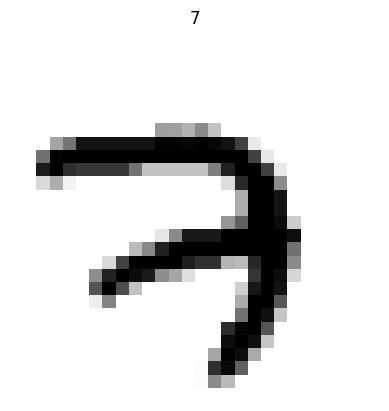

In [85]:
plt.imshow(X_train[0], cmap='binary')
plt.title(y_train[0])
plt.axis('off')
plt.show()

In [86]:
class ExponentialLearningRate(tf.keras.callbacks.Callback):
    def __init__(self, factor):
        self.factor = factor
        self.lrs = []
        self.losses = []

    def on_batch_end(self, batch, logs):
        self.lrs.append(self.model.optimizer.learning_rate.numpy())
        self.losses.append(logs['loss'])
        self.model.optimizer.learning_rate *= self.factor

In [87]:
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [88]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(300, activation='relu'),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [89]:
optimizer = tf.keras.optimizers.SGD(1e-3)
model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
              metrics=['accuracy'])

In [90]:
expon_lr = ExponentialLearningRate(1.005)
history = model.fit(X_train, y_train, epochs=1,
                    validation_data=(X_valid, y_valid),
                    callbacks=[expon_lr])

1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.5859 - loss: nan - val_accuracy: 0.0958 - val_loss: nan


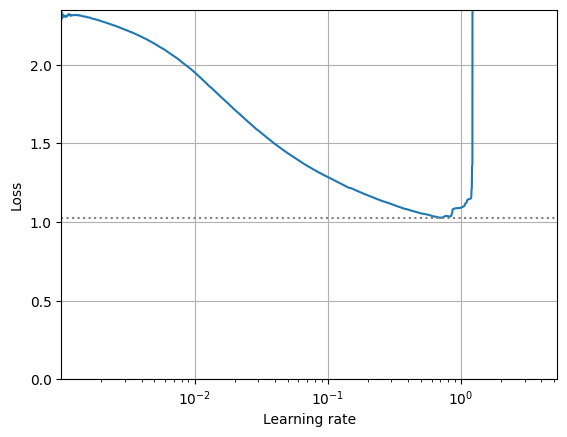

In [91]:
plt.plot(expon_lr.lrs, expon_lr.losses)
plt.axis([min(expon_lr.lrs), max(expon_lr.lrs), 0, expon_lr.losses[0]])
plt.hlines(min(expon_lr.losses), min(expon_lr.lrs), max(expon_lr.lrs), color='grey', linestyle='dotted')
plt.gca().set_xscale('log')
plt.grid()
plt.xlabel('Learning rate')
plt.ylabel('Loss')
plt.show()

In [92]:
loss_min_lr = float(expon_lr.lrs[np.argmin(expon_lr.losses)])
loss_min_lr

1.3156054019927979

In [93]:
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [94]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(300, activation='relu'),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [95]:
optimizer = tf.keras.optimizers.SGD(loss_min_lr / 2)
model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
              metrics=['accuracy'])

In [96]:
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint('my_mnist_model.keras', save_best_only=True)
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20)

history = model.fit(X_train, y_train, epochs=100,
                    validation_data=(X_valid, y_valid),
                    callbacks=[checkpoint_cb, early_stopping_cb])

Epoch 1/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 816us/step - accuracy: 0.8966 - loss: 0.3449 - val_accuracy: 0.9602 - val_loss: 0.1451
Epoch 2/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 777us/step - accuracy: 0.9583 - loss: 0.1433 - val_accuracy: 0.9656 - val_loss: 0.1166
Epoch 3/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 770us/step - accuracy: 0.9693 - loss: 0.1050 - val_accuracy: 0.9676 - val_loss: 0.1241
Epoch 4/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 776us/step - accuracy: 0.9732 - loss: 0.0908 - val_accuracy: 0.9666 - val_loss: 0.1276
Epoch 5/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 774us/step - accuracy: 0.9748 - loss: 0.0826 - val_accuracy: 0.9732 - val_loss: 0.1160
Epoch 6/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 782us/step - accuracy: 0.9769 - loss: 0.0798 - val_accuracy: 0.9720 - val_loss: 0.1258
Epoch 7/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 776us/step - accuracy: 0.9814 - loss: 0.0665 - val_accuracy: 0.9728 - val_loss: 0.1189
Epoch 8/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 775us/step - accuracy: 

In [97]:
model = tf.keras.models.load_model('my_mnist_model.keras')
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 475us/step - accuracy: 0.9691 - loss: 0.1199


[0.11987382918596268, 0.9690999984741211]